We consider the following stopping problem. We have an semi-infinite series of Bernoulli buttons. Starting with the first one at each given step we are willing to press this button or move on and press the next one. We are not allowed to return to the previous button.

We first consider the case of when we have a finite number of time steps $T$. We take that our knowledge about Bernoulli buttons is given by a Beta distribution on button success probability $\theta$

$$
P(\theta|\alpha, \beta) = \frac{\theta^{\alpha-1} (1-\theta)^{\beta-1}}{B(\alpha,\beta)}.
$$

We suppose that when we move to a new button we start with a flat prior $\alpha = 1$, $\beta = 1$. For simplicity we take that in case of succes we get a reward $1$ from pressing a button, in case of fail we get no reward.

We model the problem as a Markov Decision Process, thus we search for an optimal policy $\pi(s)$ that maximizes the expected reward

$$
V(s, T) = \mathrm{E}\left[\sum_{t = 1}^T r_{a^\pi} (s_t^{\pi}) \right].
$$

Here $s_t$ denotes our knowledge of the current button we are pressing at time $t$ and $T$ is the total number of button presses we are allowed. This knowledge can be summarized with a pair $(\alpha, \beta)$
We solve this problem via dynamical programming. The formal solution can be written as

$$
V(s, T) = \max_{a\in A}\left(r_a (s) + \sum_{s'\in S} p_a (s, s') V(s', T-1)\right),
$$

where $a$ is a particular desicion to stay or to move on, $A$ is the space of our decisions, $r_a(s)$ is the expected reward for taking an action and $V(s, 0) = 0$. Our space of states $S$ consists of our knowledge about the current button we are pressing, so it can be described with a pair $(\alpha, \beta)$ corresponding to a Beta distribution. Our space of actions consists of either pressing the current button and moving to one of the outcomes $(\alpha+1, \beta)$ or $(\alpha, \beta+1)$ with probabilities $\alpha/(\alpha + \beta)$ and $\beta/(\alpha + \beta)$ respectively, or moving to the next button and pressing it thus arriving at one of the outcomes $(2, 1)$ or $(1, 2)$ with a probability $1/2$. Labeling the expected reward from a button with a prior knowledge $(\alpha, \beta)$ and the remaining number of steps $T$ as $V(\alpha, \beta, T)$ we get the following recurrence relation

$$
V(\alpha, \beta, T) = \max \left\{
\begin{matrix}
\frac{\alpha}{\alpha + \beta} + \frac{\alpha}{\alpha + \beta} V(\alpha+1, \beta, T-1) + \frac{\beta}{\alpha + \beta} V(\alpha, \beta+1, T-1)\\
\frac{1}{2} + \frac{1}{2} V(2, 1, T-1) + \frac{1}{2} V(1, 2, T-1)
\end{matrix}\right.,
$$

and $V(\alpha, \beta, 0) = 0$. We also note that according to this definition 

$$
V(1, 1, T) = \frac{1}{2} + \frac{1}{2} V(2, 1, T-1) + \frac{1}{2} V(1, 2, T-1).
$$

The optimal policy thus corresponds to comparing

$$
\frac{\alpha}{\alpha + \beta} + \frac{\alpha}{\alpha + \beta} V(\alpha+1, \beta, T-1) + \frac{\beta}{\alpha + \beta} V(\alpha, \beta+1, T-1),
$$ 

to $V(1, 1, T)$ and moving to the next button if the latter is greater. We can evaluate the expected reward expression numerically recursively for any $T$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# A simple implementation of expected reward function
# It outputs 3D numpy array, the first index corresponds to number of button presses left
# Second and third indices correspon to values of alpha and beta
# You need to add 1 to indices values to get function arguments
# e.g val[5,3,2] corresponds to V(alpha = 4, beta = 3, T = 4)
# Function argument max_ab corresponds to maximal values of alpha and beta in the table
# Argument time corresponds to maximal time step

def expected_reward_table(max_ab, time):
    size = max_ab+time
    val = np.zeros((time, max_ab, max_ab))

    arr = np.zeros((size, size))
    for i in range(size):
        for j in range(size):
            arr[i, j] = (i+1.)/(i+j+2.)
            
    val[0] = arr[:max_ab, :max_ab]
    for t in range(time-1):
        move_val = 0.5 + 0.5*(arr[1, 0] + arr[0, 1])
        for i in range(size - t - 1):
            for j in range(size - t - 1):
                stay_val = (i+1)/(i+j+2) + (i+1)/(i+j+2)*arr[i+1,j] + (j+1)/(i+j+2)*arr[i,j+1]
                arr[i,j] = max(move_val, stay_val)
        val[t+1] = arr[:max_ab, :max_ab]
        
    return val

In [2]:
# Here we run the above function
val = expected_reward_table(10, 250)

In [3]:
# V(alpha, beta) for some sample time step T = 5
print(np.array_str(val[4], precision=4))

[[3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278]
 [3.4444 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278]
 [3.7667 3.1333 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278]
 [4.     3.3571 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278]
 [4.1667 3.5714 3.1667 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278]
 [4.2857 3.75   3.3374 3.0606 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278]
 [4.375  3.8889 3.5    3.1896 3.0278 3.0278 3.0278 3.0278 3.0278 3.0278]
 [4.4444 4.     3.6364 3.3333 3.0952 3.0278 3.0278 3.0278 3.0278 3.0278]
 [4.5    4.0909 3.75   3.4615 3.2143 3.0333 3.0278 3.0278 3.0278 3.0278]
 [4.5455 4.1667 3.8462 3.5714 3.3333 3.125  3.0278 3.0278 3.0278 3.0278]]


We see that if the number of fails is greater or equal to the number of successes it is always better to move on to the next button

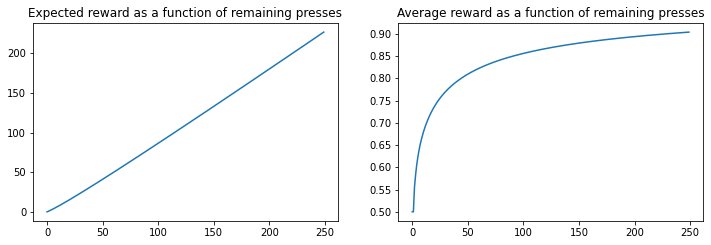

In [4]:
fig = plt.figure(figsize = (12,8))
ax = fig.add_subplot(221)
ax.set_title("Expected reward as a function of remaining presses")
ax.plot(val[:,0,0]);

val_avg = np.copy(val[:,0,0])
val_avg = val_avg/np.arange(1,len(val_avg)+1)

ax = fig.add_subplot(222)
ax.set_title("Average reward as a function of remaining presses")
ax.plot(val_avg);

In case of Bernoulli bandit starting from a flat prior we find the following interesting pattern.
If we take a button for which we have only seen successes before, it is always better to stay with this button.
If we then consider a button for which we have seen some fails (and the amount of successes is greater than the number of fails) then for some small number of remaining presses T it is better to stay with this button. However, for some sufficiently large T it is actually better to move on to the next button right away.

In [5]:
# We demonstrate it for the case where we have seen 6 successes and 1 fail. We see that at some point in time
# it is actually better to move to a new button

print("The time T for which it is better to move on:", np.where(val[:,5,1]-val[:,0,0] == 0.0)[0][0])

The time T for which it is better to move on: 189


In [6]:
print(val[:,5,1]-val[:,0,0])

[2.50000000e-01 5.00000000e-01 5.83333333e-01 6.66666667e-01
 7.22222222e-01 7.64898990e-01 7.93476431e-01 8.14202927e-01
 8.29977353e-01 8.39908741e-01 8.43514470e-01 8.43509694e-01
 8.43262340e-01 8.41053263e-01 8.34417200e-01 8.27157583e-01
 8.17010507e-01 8.04437215e-01 7.93631494e-01 7.86334781e-01
 7.78120447e-01 7.69282680e-01 7.59655463e-01 7.49080524e-01
 7.39564975e-01 7.30028783e-01 7.19819976e-01 7.09268479e-01
 6.98029081e-01 6.87555833e-01 6.76827996e-01 6.67516436e-01
 6.59140963e-01 6.50811690e-01 6.42657914e-01 6.34642370e-01
 6.26292911e-01 6.17677238e-01 6.09117269e-01 6.00368741e-01
 5.91396048e-01 5.83127214e-01 5.75029909e-01 5.66729432e-01
 5.58180760e-01 5.49537664e-01 5.40969911e-01 5.33274779e-01
 5.25938241e-01 5.18698858e-01 5.11471465e-01 5.04442806e-01
 4.97484846e-01 4.90473157e-01 4.83480548e-01 4.76561138e-01
 4.69780330e-01 4.62942261e-01 4.55999541e-01 4.49056115e-01
 4.42319083e-01 4.35552699e-01 4.28866349e-01 4.22502463e-01
 4.16223593e-01 4.100445